# CycloPepper Model Training and Evaluation (Phase 2)

**Purpose:** Independently compare Dummy Classifier, Logistic Regression, and Random Forest using simplified peptide sequence features and cyclic rotation-aware data splitting.

**Data source:** The public `dataset.csv` from [Pan et al. (2026)](https://doi.org/10.1038/s41467-026-69441-w), available in the [original repository](https://github.com/Yongboxiao/Selection-of-Cyclization-Sites).

**Study design:** Extract 61 features per sequence (length, 20 amino acid fractions, 20 N-terminal indicators, and 20 C-terminal indicators). Use a group-based train/test split, five-fold GroupKFold cross-validation on the training data, and a separate holdout test for all three predefined models.

**Scope:** This is an independent evaluation of simplified classification models, not a reproduction of the full CycloPepper platform. Experimental `Score` is binary and indicates LC-MS detection of an expected product-mass signal; it is not a quantitative yield measurement. The external `experiment.csv` has no `Score` column and is not used for accuracy evaluation.

**How to run:** Open in Google Colab and select **Runtime → Run all**. This notebook does not require Phase 1 or a GPU. If the public data download fails, the notebook asks for a local copy of `dataset.csv`.

**Outputs:** `CycloPepper_Phase2_All_Results.zip` containing the model metrics, predictions, data summary, and figures. This archive is the input to Phase 3.


In [ ]:
# 1. Setup and dependencies
%pip -q install pandas numpy scikit-learn matplotlib openpyxl
import io, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
SEED=42
np.random.seed(SEED)
OUT=Path('cyclopepper_phase2_outputs');OUT.mkdir(exist_ok=True)
print('Ready. Output directory:',OUT)


Ready. Output directory: cyclopepper_phase2_outputs


## 2. Load and inspect the dataset

Load `dataset.csv` from the original public repository. If the download is unavailable, upload a local copy when prompted. Check missing or invalid values and report duplicate or conflicting records. The notebook does not silently remove exact duplicate records.


In [ ]:
RAW='https://raw.githubusercontent.com/Yongboxiao/Selection-of-Cyclization-Sites/main/dataset.csv'
try:
    raw=pd.read_csv(RAW,encoding='utf-8-sig')
    print('Loaded from official GitHub raw URL')
except Exception as e:
    print('Network download failed:',str(e)[:250]); print('Upload dataset.csv now:')
    from google.colab import files
    uploaded=files.upload()
    if 'dataset.csv' not in uploaded: raise ValueError('Please upload dataset.csv')
    raw=pd.read_csv(io.BytesIO(uploaded['dataset.csv']),encoding='utf-8-sig')
print('Raw shape:',raw.shape,'Columns:',list(raw.columns))
assert {'Sequence','Score'}.issubset(raw.columns), 'Required columns: Sequence, Score'
raw['Sequence']=raw['Sequence'].astype('string').str.strip().str.upper()
raw['Score']=pd.to_numeric(raw['Score'],errors='coerce')
bad=raw['Sequence'].isna()|raw['Sequence'].eq('')|raw['Score'].isna()|~raw['Score'].isin([0,1])
print('Invalid or missing rows:',int(bad.sum()))
df=raw.loc[~bad,['Sequence','Score']].copy().reset_index(drop=True)
df['Score']=df['Score'].astype(int)
print('Valid records:',len(df),'Label frequencies:');display(df.Score.value_counts().sort_index().rename('count').to_frame())
print('Exact duplicate rows:',int(df.duplicated(['Sequence','Score']).sum()))
print('Sequences with conflicting labels:',int((df.groupby('Sequence').Score.nunique()>1).sum()))
if bad.sum(): print('WARNING: invalid/missing records excluded; see previous count')
display(df.head())


Loaded from official GitHub raw URL
Raw shape: (306, 2) Columns: ['Sequence', 'Score']
Invalid or missing rows: 0
Valid records: 306 Label frequencies:


,count
Score,
0,132
1,174


Exact duplicate rows: 2
Sequences with conflicting labels: 1


,Sequence,Score
0,RG,1
1,HG,1
2,NG,1
3,QG,1
4,FW,1


## 3. Group cyclic rotations and extract features

Cyclic shifts such as ABCD, BCDA, CDAB, and DABC share one rotation-group identifier. Group membership is used to reduce potential data leakage; individual records and their experimental labels are not merged.

Each sequence is represented by 61 features: sequence length, relative frequencies of the 20 standard amino acids, and 20 one-hot features for each terminal residue. The terminal indicators retain information about the linear precursor's starting and ending positions.


In [ ]:
AA=list('ACDEFGHIKLMNPQRSTVWY')
def rotation_key(s):
    return min(s[i:]+s[:i] for i in range(len(s)))
df['rotation_group']=df.Sequence.map(rotation_key)
invalid_aa=~df.Sequence.map(lambda s:len(s)>0 and all(ch in AA for ch in s))
print('Sequences containing nonstandard amino acid symbols:',int(invalid_aa.sum()))
if invalid_aa.any():
    display(df.loc[invalid_aa,['Sequence','Score']].head(10))
    print('Removing nonstandard sequences because the simple descriptor uses 20 standard amino acids')
    df=df.loc[~invalid_aa].reset_index(drop=True)
print('Records for modeling:',len(df),'Rotation groups:',df.rotation_group.nunique())
print('Groups with conflicting scores:',int((df.groupby('rotation_group').Score.nunique()>1).sum()))

def featurize(seq):
    length=len(seq)
    d={'length':length}
    d.update({'frac_'+a:seq.count(a)/length for a in AA})
    d.update({'N_'+a:int(seq[0]==a) for a in AA})
    d.update({'C_'+a:int(seq[-1]==a) for a in AA})
    return d
X=pd.DataFrame([featurize(s) for s in df.Sequence],index=df.index)
y=df.Score.to_numpy();groups=df.rotation_group.to_numpy()
print('Feature matrix:',X.shape)


Sequences containing nonstandard amino acid symbols: 0
Records for modeling: 306 Rotation groups: 277
Groups with conflicting scores: 8
Feature matrix: (306, 61)


## 4. Create a rotation-group-independent holdout set

Use `GroupShuffleSplit` with a target of approximately 80% training and 20% testing, while keeping each rotation group entirely in one set. The test set is reserved for final evaluation and is not used to tune the models.


In [ ]:
split=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED)
train_idx,test_idx=next(split.split(X,y,groups))
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test=y[train_idx],y[test_idx]
g_train,g_test=groups[train_idx],groups[test_idx]
assert set(g_train).isdisjoint(set(g_test))
print(f'Train: {len(train_idx)} rows, {len(set(g_train))} rotation groups; label counts:',dict(pd.Series(y_train).value_counts().sort_index()))
print(f'Test: {len(test_idx)} rows, {len(set(g_test))} rotation groups; label counts:',dict(pd.Series(y_test).value_counts().sort_index()))
if len(np.unique(y_train))<2:raise ValueError('Only one train label; change SEED and re-run all.')
if len(np.unique(y_test))<2:print('WARNING: test set has only one label; ROC AUC will be undefined.')


Train: 246 rows, 221 rotation groups; label counts: {0: np.int64(101), 1: np.int64(145)}
Test: 60 rows, 56 rotation groups; label counts: {0: np.int64(31), 1: np.int64(29)}


## 5. Compare models with five-fold grouped cross-validation

Evaluate the same 61 sequence features with three predefined models: a most-frequent-class Dummy baseline, standardized Logistic Regression, and Random Forest. Use `GroupKFold` on the training portion only.


In [ ]:
models={
    'Dummy (most frequent)':DummyClassifier(strategy='most_frequent'),
    'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED)),
    'Random Forest':RandomForestClassifier(n_estimators=300,max_depth=None,min_samples_leaf=3,class_weight='balanced',random_state=SEED,n_jobs=-1)
}
n_folds=min(5,len(set(g_train)))
cv=GroupKFold(n_splits=n_folds)
scoring={'accuracy':'accuracy','balanced_accuracy':'balanced_accuracy','f1':'f1'}
cv_rows=[]
for name,model in models.items():
    print('Cross-validating:',name)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        s=cross_validate(model,X_train,y_train,groups=g_train,cv=cv,scoring=scoring,error_score='raise')
    row={'Model':name,'CV_folds':n_folds}
    for metric in scoring:
        vals=s['test_'+metric];row['CV_'+metric+'_mean']=float(vals.mean());row['CV_'+metric+'_std']=float(vals.std())
    cv_rows.append(row)
cv_results=pd.DataFrame(cv_rows)
display(cv_results.round(3))
cv_results.to_csv(OUT/'cross_validation_results.csv',index=False,encoding='utf-8-sig')


Cross-validating: Dummy (most frequent)
Cross-validating: Logistic Regression
Cross-validating: Random Forest


,Model,CV_folds,CV_accuracy_mean,CV_accuracy_std,CV_balanced_accuracy_mean,CV_balanced_accuracy_std,CV_f1_mean,CV_f1_std
0,Dummy (most frequent),5,0.590,0.065,0.500,0.000,0.740,0.051
1,Logistic Regression,5,0.589,0.034,0.580,0.024,0.631,0.061
2,Random Forest,5,0.658,0.084,0.651,0.081,0.703,0.070


## 6. Evaluate all models on the held-out test set

Fit each predefined model on the training set and report its holdout performance. This notebook does not conduct a hyperparameter search on the test set.


In [ ]:
fitted={};results=[];pred_table=df.iloc[test_idx][['Sequence','Score','rotation_group']].reset_index(drop=True).copy()
for name,model in models.items():
    model.fit(X_train,y_train)
    fitted[name]=model
    yp=model.predict(X_test)
    prob=model.predict_proba(X_test)[:,list(model.classes_).index(1)] if hasattr(model,'predict_proba') else np.full(len(yp),np.nan)
    auc=roc_auc_score(y_test,prob) if len(np.unique(y_test))==2 and np.isfinite(prob).all() else np.nan
    results.append({'Model':name,'Test_accuracy':accuracy_score(y_test,yp),
                    'Test_balanced_accuracy':balanced_accuracy_score(y_test,yp),
                    'Test_F1':f1_score(y_test,yp,zero_division=0),'Test_ROC_AUC':auc})
    key=name.replace(' ','_').replace('(','').replace(')','')
    pred_table[key+'_pred']=yp
    pred_table[key+'_prob1']=prob
holdout_results=pd.DataFrame(results)
display(holdout_results.round(3))
pred_table.to_csv(OUT/'holdout_predictions.csv',index=False,encoding='utf-8-sig')
holdout_results.to_csv(OUT/'holdout_metrics.csv',index=False,encoding='utf-8-sig')


,Model,Test_accuracy,Test_balanced_accuracy,Test_F1,Test_ROC_AUC
0,Dummy (most frequent),0.483,0.500,0.652,0.500
1,Logistic Regression,0.617,0.621,0.657,0.630
2,Random Forest,0.650,0.651,0.656,0.727


## 7. Generate evaluation figures

Generate plots for label distribution, grouped cross-validation, holdout Balanced Accuracy, and the Random Forest confusion matrix. The plots are saved as PNG files and may be reformatted for the report.


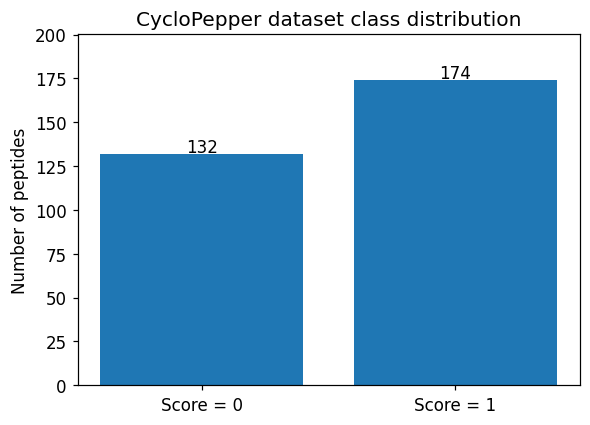

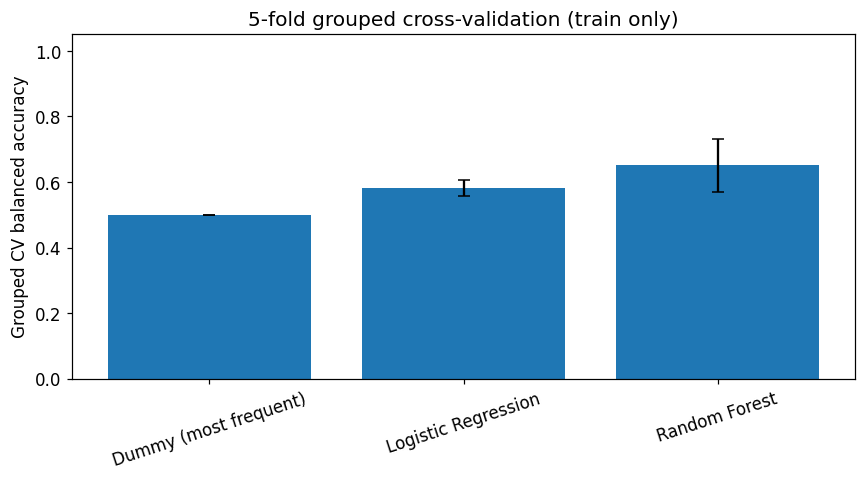

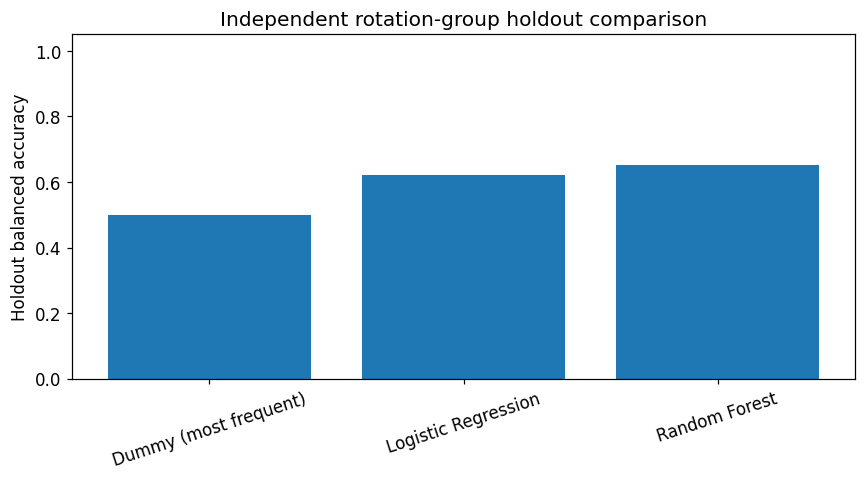

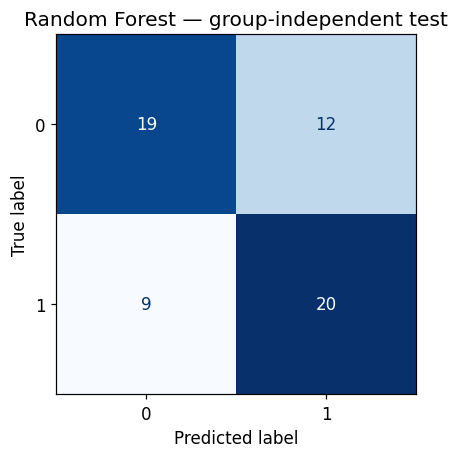

In [ ]:
plt.rcParams.update({'font.size':11,'figure.dpi':110})
fig,ax=plt.subplots(figsize=(5.5,4))
counts=df.Score.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Score = 0','Score = 1'],counts.values)
for i,v in enumerate(counts.values):ax.text(i,v+1,str(v),ha='center')
ax.set(ylabel='Number of peptides',title='CycloPepper dataset class distribution')
ax.set_ylim(0,max(counts)*1.15);fig.tight_layout();fig.savefig(OUT/'figure_class_distribution.png',dpi=300);plt.show()

fig,ax=plt.subplots(figsize=(8,4.5))
ax.bar(cv_results.Model,cv_results.CV_balanced_accuracy_mean,yerr=cv_results.CV_balanced_accuracy_std,capsize=4)
ax.set(ylabel='Grouped CV balanced accuracy',title=f'{n_folds}-fold grouped cross-validation (train only)',ylim=(0,1.05))
ax.tick_params(axis='x',labelrotation=18);fig.tight_layout();fig.savefig(OUT/'figure_cv_comparison.png',dpi=300);plt.show()

fig,ax=plt.subplots(figsize=(8,4.5))
ax.bar(holdout_results.Model,holdout_results.Test_balanced_accuracy)
ax.set(ylabel='Holdout balanced accuracy',title='Independent rotation-group holdout comparison',ylim=(0,1.05))
ax.tick_params(axis='x',labelrotation=18);fig.tight_layout();fig.savefig(OUT/'figure_holdout_comparison.png',dpi=300);plt.show()

fig,ax=plt.subplots(figsize=(5,4.3))
ConfusionMatrixDisplay.from_predictions(y_test,fitted['Random Forest'].predict(X_test),labels=[0,1],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Random Forest — group-independent test')
fig.tight_layout();fig.savefig(OUT/'figure_rf_confusion_matrix.png',dpi=300);plt.show()


## 8. Interpretation and result exports

- The dataset is relatively small, so performance may change with a different data split.
- GroupKFold keeps members of the same cyclic rotation group together, but does not eliminate every possible similarity between sequences.
- These 61 features are simpler than the original CycloPepper feature set. Results must not be presented as a direct reproduction of the original study's reported accuracy.
- Binary experimental labels are not direct measurements of product yield or purity.
- External performance evaluation requires matched experimental outcomes for the 74 sequence records in `experiment.csv`.

The exported metrics and predictions are used in Phase 3 to examine cyclic rotation groups and data consistency.


In [ ]:
# 8. Export an Excel workbook, figures, and result archive
summary=pd.DataFrame([{
    'dataset_rows':len(df),'n_rotation_groups':df.rotation_group.nunique(),
    'train_rows':len(train_idx),'test_rows':len(test_idx),
    'train_groups':len(set(g_train)),'test_groups':len(set(g_test)),
    'random_seed':SEED,
    'note':'Group-independent holdout; simplified peptide sequence descriptors, not original CycloPepper model'
}])
with pd.ExcelWriter(OUT/'CycloPepper_Phase2_Results.xlsx',engine='openpyxl') as w:
    summary.to_excel(w,sheet_name='Dataset_Summary',index=False)
    cv_results.to_excel(w,sheet_name='Grouped_CV',index=False)
    holdout_results.to_excel(w,sheet_name='Holdout_Metrics',index=False)
    pred_table.to_excel(w,sheet_name='Test_Predictions',index=False)
    df.to_excel(w,sheet_name='Cleaned_Data',index=False)
import shutil
zip_path=shutil.make_archive('CycloPepper_Phase2_All_Results','zip',OUT)
print('Saved:',OUT/'CycloPepper_Phase2_Results.xlsx')
print('Saved archive:',zip_path)
try:
    from google.colab import files
    files.download(zip_path) # One download contains Excel + PNG + CSV
except ImportError:
    print('Run in Colab to download automatically; files saved locally.')


Saved: cyclopepper_phase2_outputs/CycloPepper_Phase2_Results.xlsx
Saved archive: /content/CycloPepper_Phase2_All_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Output files and next phase

Download `CycloPepper_Phase2_All_Results.zip` after execution. It includes model metrics, holdout predictions, figures, and an Excel workbook containing the cleaned data and group identifiers.

For the next step, open **Phase 3: Cyclization-Site and Label Consistency Analysis** in Google Colab and upload this archive when prompted. Phase 3 reuses the saved results and does not retrain the models.
